# AR aggregation ablation (species subset)

Compares alternative rules for combining the per-dimension AR weights into one weight per cell.

Data: `data/species_for_AR_example.h5ad`.

For every latent dimension $k$, AR bins the latent values into a histogram, smooths and inverts the bin densities and normalizes them over cells, giving per-dimension weights $u^*_{kn}$. The rules below differ only in how these are combined into one weight $w_n$ per cell (all rules are in `scripts/ar_aggregation_variants.py`). sc-AR uses the **maximum**, the rule of the MIT 6.S191 (2019) DB-VAE course implementation of Amini et al. and its 2021 reproduction, which the sc-AR code adapts.

| Method | Weight $w_n$ (normalized to sum to 1) |
|---|---|
| **Standard** | no resampling; shuffled minibatches |
| **AR-uniform** | $1/N$: resampling with replacement, no density weights |
| **AR-max** | $\max_k u^*_{kn}$ (**sc-AR default**) |
| **AR-mean** | $\mathrm{mean}_k\, u^*_{kn}$ |
| **AR-geomean** | $\exp(\mathrm{mean}_k \log u^*_{kn})$ |
| **AR-knn** | mean distance to the $k$ nearest neighbours in the full latent space (rotation-invariant joint-density proxy) |

Every AR variant uses the same training loop: at the start of each epoch the weights are computed from the latent space of all training cells, one resampled training set of size $N$ is drawn with replacement, and the model is trained on it in minibatches (Algorithm 1). Each method is trained with several seeds.

Reported on the validation set: population MSE (mean over cells), **macro MSE** (mean over cell types, which highlights rare populations) and MSE of the rarest cell types.

This is a **mini analysis** on a small autoencoder, not a full benchmark.

### Imports

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.stats import ttest_rel
from sklearn.model_selection import train_test_split

# run from the repository root
ROOT = Path.cwd().resolve()
if not (ROOT / "scripts" / "ar_aggregation_variants.py").exists():
    raise FileNotFoundError(f"Run this notebook from the sc-AR repository root (cwd: {ROOT})")
sys.path.insert(0, str(ROOT))

from scripts.ar_aggregation_variants import calculate_resampling_weights_with_method

OUT_DIR = ROOT / "result" / "ar_aggregation_ablation"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("outputs:", OUT_DIR)

outputs: result/ar_aggregation_ablation


### Load data

We use a ready-made subset of the species data: `data/species_for_AR_example.h5ad` (~5,000 cells × 2,000 HVGs, imbalanced Louvain populations in `obs["str_labels"]`). Expression is already library-size normalized and log1p-transformed.

If the file is missing, build it with:

```bash
python scripts/make_species_for_AR_example.py \
  --input data/species.h5ad \
  --output data/species_for_AR_example.h5ad
```

In [2]:
SPLIT_SEED = 42  # one fixed train/validation split for all methods and seeds
DATA_PATH = ROOT / "data" / "species_for_AR_example.h5ad"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Build it with:\n"
        "  python scripts/make_species_for_AR_example.py "
        "--input data/species.h5ad --output data/species_for_AR_example.h5ad"
    )

adata = sc.read_h5ad(DATA_PATH)
label_col = "str_labels"
assert label_col in adata.obs.columns

print(f"Species subset shape: {adata.shape}")
print("\nCell population distribution:")
print(adata.obs[label_col].value_counts().to_string())
imb = adata.obs[label_col].value_counts()
print(f"\nImbalance ratio (largest / smallest): {imb.max() / imb.min():.0f}x")

Species subset shape: (5085, 2000)

Cell population distribution:
str_labels
clust_0     2500
clust_1     1200
clust_2      600
clust_3      300
clust_7      150
clust_8       90
clust_9       60
clust_4       45
clust_5       35
clust_6       28
clust_10      22
clust_13      18
clust_11      15
clust_12      12
clust_14      10

Imbalance ratio (largest / smallest): 250x


In [3]:
X = adata.X.toarray().astype("float32") if hasattr(adata.X, "toarray") else np.asarray(adata.X, dtype="float32")
y = adata.obs[label_col].astype(str).to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SPLIT_SEED, stratify=y
)
X_train_t = torch.tensor(X_train)
X_val_t = torch.tensor(X_val)

print(f"Train: {X_train.shape}  |  Val: {X_val.shape}")
print("\nValidation cell-type counts:")
print(pd.Series(y_val).value_counts().to_string())

Train: (4068, 2000)  |  Val: (1017, 2000)

Validation cell-type counts:
clust_0     500
clust_1     240
clust_2     120
clust_3      60
clust_7      30
clust_8      18
clust_9      12
clust_4       9
clust_5       7
clust_6       6
clust_13      4
clust_10      4
clust_11      3
clust_14      2
clust_12      2


### Model and helpers

The model returns `forward(x) -> (reconstruction, z)`; the AR weights are computed from `z`.

In [4]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


class CustomAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, hidden_dim=64, dropout_rate=0.1):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, input_dim), nn.Softplus(),
        )

    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z)
        return recon, z


def per_celltype_mse(model, X_t, labels, device):
    model.eval()
    with torch.no_grad():
        recon, _ = model(X_t.to(device))
        cell_mse = ((recon - X_t.to(device)) ** 2).mean(dim=1).cpu().numpy()
    return pd.DataFrame({"celltype": labels, "mse": cell_mse}).groupby("celltype")["mse"].mean()


def evaluate(model, X_val_t, val_labels, loss_fn, device):
    model.eval()
    with torch.no_grad():
        recon_val, _ = model(X_val_t.to(device))
        val_loss = loss_fn(recon_val, X_val_t.to(device)).item()
    return val_loss, per_celltype_mse(model, X_val_t, val_labels, device).mean()


def train(
    model,
    X_train_t,
    X_val_t,
    val_labels,
    num_epochs,
    batch_size,
    lr,
    weight_decay,
    device,
    seed,
    aggregation=None,
    bins=100,
    smoothing_fac=0.0001,
    knn_k=30,
    loss_fn=None,
):
    # Standard training (aggregation=None) or AR training with one of the
    # rules in scripts/ar_aggregation_variants.py. AR: at the start of every
    # epoch, weights from the latent space of all training cells, one
    # resampled training set of size N (with replacement), then minibatches.
    if loss_fn is None:
        loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    n_train = len(X_train_t)
    rng = np.random.default_rng(seed)  # resampling
    loader = DataLoader(TensorDataset(X_train_t), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = {"train_loss": [], "val_loss": [], "macro_val_loss": []}

    for epoch in range(num_epochs):
        if aggregation is None:
            batches = (batch for (batch,) in loader)
        else:
            model.eval()
            with torch.no_grad():
                _, z = model(X_train_t.to(device))
            w = calculate_resampling_weights_with_method(
                z.cpu().numpy(),
                method=aggregation,
                bins=bins,
                smoothing_fac=smoothing_fac,
                knn_k=knn_k,
            )
            epoch_idx = rng.choice(n_train, size=n_train, replace=True, p=w)
            batches = (X_train_t[epoch_idx[i:i + batch_size]]
                       for i in range(0, n_train, batch_size))

        model.train()
        running_loss = 0.0
        n_seen = 0
        for batch in batches:
            batch = batch.to(device)
            optimizer.zero_grad()
            recon, _ = model(batch)
            loss = loss_fn(recon, batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * batch.size(0)
            n_seen += batch.size(0)
        history["train_loss"].append(running_loss / n_seen)

        val_loss, macro_val = evaluate(model, X_val_t, val_labels, loss_fn, device)
        history["val_loss"].append(val_loss)
        history["macro_val_loss"].append(macro_val)

        if (epoch + 1) % 50 == 0:
            print(
                f"  Epoch [{epoch+1:3d}/{num_epochs}]  train={history['train_loss'][-1]:.4f}  "
                f"val={val_loss:.4f}  macro_val={macro_val:.4f}"
            )
    return history

### Hyperparameters

In [5]:
LATENT_DIM = 8
HIDDEN_DIM = 64
BATCH_SIZE = 128
NUM_EPOCHS = 100  # mini ablation; increase for smoother curves
LR = 1e-3
DROPOUT = 0.1
WEIGHT_DECAY = 1e-4

BINS = 100
SMOOTHING = 0.0001  # sc-AR default
KNN_K = 30

SEEDS = [0, 1, 2, 3, 4]

N_RARE_TYPES = 3
rare_types = (
    pd.Series(y_train).value_counts().sort_values().index[:N_RARE_TYPES].tolist()
)
print(f"Rare cell types (smallest {N_RARE_TYPES}): {rare_types}")

METHODS = [
    ("Standard", None),
    ("AR-uniform", "uniform"),
    ("AR-max", "max"),
    ("AR-mean", "mean"),
    ("AR-geomean", "geomean"),
    ("AR-knn", "knn"),
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Rare cell types (smallest 3): ['clust_14', 'clust_12', 'clust_11']
Device: cpu


### Train Standard and AR aggregation variants

In [6]:
rows = []
per_celltype = {}

for seed in SEEDS:
    for name, agg in METHODS:
        print(f"=== seed {seed} | {name}" + ("" if agg is None else f" (aggregation={agg})"))
        set_seed(seed)  # same initial weights for every method within a seed
        model = CustomAutoencoder(
            input_dim=X_train.shape[1],
            latent_dim=LATENT_DIM,
            hidden_dim=HIDDEN_DIM,
            dropout_rate=DROPOUT,
        ).to(device)

        history = train(
            model, X_train_t, X_val_t, y_val,
            num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE,
            lr=LR, weight_decay=WEIGHT_DECAY, device=device, seed=seed,
            aggregation=agg, bins=BINS, smoothing_fac=SMOOTHING, knn_k=KNN_K,
        )

        mse = per_celltype_mse(model, X_val_t, y_val, device)
        per_celltype[(name, seed)] = mse
        rows.append({
            "method": name,
            "seed": seed,
            "population_mse": history["val_loss"][-1],
            "macro_mse": float(mse.mean()),
            "rare_mse": float(mse.reindex(rare_types).mean()),
        })
        print(
            f"Final: pop_val={rows[-1]['population_mse']:.4f}  "
            f"macro_val={rows[-1]['macro_mse']:.4f}  rare_val={rows[-1]['rare_mse']:.4f}"
        )

results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "ar_aggregation_ablation_per_seed.csv", index=False)
print("saved", OUT_DIR / "ar_aggregation_ablation_per_seed.csv")

=== seed 0 | Standard
  Epoch [ 50/100]  train=0.0885  val=0.0823  macro_val=0.1012
  Epoch [100/100]  train=0.0874  val=0.0817  macro_val=0.0999
Final: pop_val=0.0817  macro_val=0.0999  rare_val=0.1593
=== seed 0 | AR-uniform (aggregation=uniform)
  Epoch [ 50/100]  train=0.0882  val=0.0824  macro_val=0.1010
  Epoch [100/100]  train=0.0883  val=0.0819  macro_val=0.1002
Final: pop_val=0.0819  macro_val=0.1002  rare_val=0.1595
=== seed 0 | AR-max (aggregation=max)
  Epoch [ 50/100]  train=0.0973  val=0.0831  macro_val=0.0983
  Epoch [100/100]  train=0.1026  val=0.0825  macro_val=0.0983
Final: pop_val=0.0825  macro_val=0.0983  rare_val=0.1589
=== seed 0 | AR-mean (aggregation=mean)
  Epoch [ 50/100]  train=0.0924  val=0.0818  macro_val=0.0981
  Epoch [100/100]  train=0.0916  val=0.0810  macro_val=0.0971
Final: pop_val=0.0810  macro_val=0.0971  rare_val=0.1541
=== seed 0 | AR-geomean (aggregation=geomean)
  Epoch [ 50/100]  train=0.0949  val=0.0822  macro_val=0.0999
  Epoch [100/100]  tra

### Summary table

Mean ± SD over seeds. Paired comparisons use seed-matched pairs (same seed = same initial weights and data split): mean paired difference of macro MSE against Standard and against AR-max (negative = lower error than the reference), two-sided paired t-test, and the number of seeds in which the method has a lower macro MSE than Standard.

In [7]:
method_order = [name for name, _ in METHODS]
metrics = ["population_mse", "macro_mse", "rare_mse"]

summary = (results.groupby("method")[metrics].agg(["mean", "std"])
           .reindex(method_order))
summary.columns = [f"{m} {s}" for m, s in summary.columns]

macro = results.pivot(index="seed", columns="method", values="macro_mse")
for ref in ["Standard", "AR-max"]:
    diff = macro.sub(macro[ref], axis=0)
    summary[f"macro diff vs {ref}"] = diff.mean()
    summary[f"p vs {ref}"] = [
        np.nan if m == ref else ttest_rel(macro[m], macro[ref]).pvalue for m in method_order
    ]
summary["seeds better than Standard"] = [
    np.nan if m == "Standard" else int((macro[m] < macro["Standard"]).sum()) for m in method_order
]

print(summary.round(4).to_string())
summary.to_csv(OUT_DIR / "ar_aggregation_ablation_summary.csv")
print("saved", OUT_DIR / "ar_aggregation_ablation_summary.csv")

            population_mse mean  population_mse std  macro_mse mean  macro_mse std  rare_mse mean  rare_mse std  macro diff vs Standard  p vs Standard  macro diff vs AR-max  p vs AR-max  seeds better than Standard
method                                                                                                                                                                                                               
Standard                 0.0813              0.0006          0.0996         0.0007         0.1588        0.0013                  0.0000            NaN                0.0009       0.0403                         NaN
AR-uniform               0.0814              0.0005          0.0996         0.0007         0.1591        0.0013                 -0.0000         0.8956                0.0009       0.0657                         3.0
AR-max                   0.0822              0.0004          0.0987         0.0003         0.1576        0.0021                 -0.0009         

### Per-cell-type reconstruction

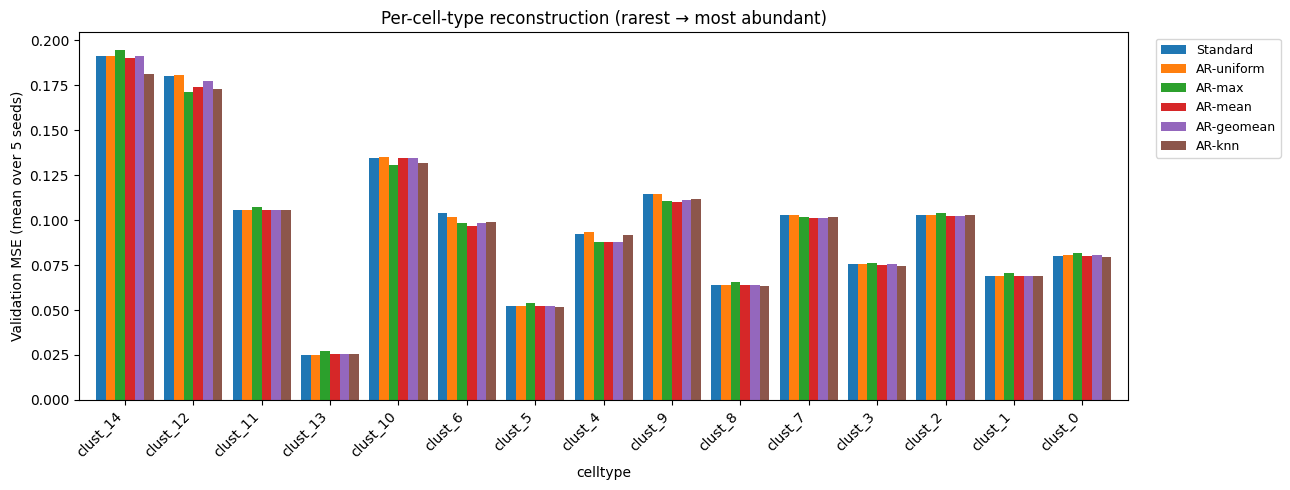

saved result/ar_aggregation_ablation/ar_aggregation_ablation_per_celltype_mse.png


In [8]:
order = pd.Series(y_train).value_counts().sort_values().index.tolist()
mse_df = pd.DataFrame({
    name: pd.concat([per_celltype[(name, s)] for s in SEEDS], axis=1).mean(axis=1)
    for name in method_order
}).reindex(order)

ax = mse_df.plot(kind="bar", figsize=(13, 5), width=0.85)
ax.set_ylabel(f"Validation MSE (mean over {len(SEEDS)} seeds)")
ax.set_title("Per-cell-type reconstruction (rarest → most abundant)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig_path = OUT_DIR / "ar_aggregation_ablation_per_celltype_mse.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("saved", fig_path)
